# PCL Detection

In [ ]:
import re
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    precision_recall_curve, average_precision_score
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed, EarlyStoppingCallback
)

# for reproducibility
GLOBAL_SEED = 42
set_seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

./venv_nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [ ]:
# Configuration
CFG = {
    "model_name"       : "roberta-large",
    "max_len"          : 256,
    "batch_size"       : 4,
    "grad_accum"       : 2, 
    "lr"               : 1e-5,
    "weight_decay"     : 0.01,
    "warmup_ratio"     : 0.1,
    "epochs"           : 6,
    "patience"         : 2,
    "llrd_decay"       : 0.95,
    "focal_alpha"      : 0.8,
    "focal_gamma"      : 2.0,
    "seeds"            : [42, 7, 21],
    "checkpoint_dir"   : "./checkpoints",
}

os.makedirs(CFG["checkpoint_dir"], exist_ok=True)
print(json.dumps(CFG, indent=2))

{
  "model_name": "roberta-large",
  "max_len": 256,
  "batch_size": 4,
  "grad_accum": 2,
  "lr": 1e-05,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "epochs": 6,
  "patience": 2,
  "llrd_decay": 0.95,
  "focal_alpha": 0.8,
  "focal_gamma": 2.0,
  "seeds": [
    42,
    7,
    21
  ],
  "checkpoint_dir": "./checkpoints"
}


## Data Loading & Preprocessing


In [ ]:
def clean_text(text):
    """Remove dataset artifacts and normalize whitespace."""
    text = re.sub(r'@@\d+', '', str(text))
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def build_prompt(row):
    """
    Natural-language prompt that grounds the model in the demographic context.
    Format: 'Context: <keyword> in <country>. Statement: <text>'
    I was motivated by EDA showing keyword+country are predictive of PCL.
    """
    return f"Context: {row['keyword']} in {row['country_code']}. Statement: {clean_text(row['text'])}"


def load_data():
    df_raw = pd.read_csv(
        './NLPLabs-2024/Dont_Patronize_Me_Trainingset/dontpatronizeme_pcl.tsv', sep='\t', skiprows=4, header=None,
        names=['par_id', 'art_id', 'keyword', 'country_code', 'text', 'label'],
        quoting=3
    )
    df_raw.dropna(subset=['text', 'label'], inplace=True)
    df_raw['label_binary'] = (pd.to_numeric(df_raw['label'], errors='coerce') >= 2).astype(int)
    df_raw.dropna(subset=['label_binary'], inplace=True)
    df_raw['processed_text'] = df_raw.apply(build_prompt, axis=1)
    train_ids = pd.read_csv('./dontpatronizeme/semeval-2022/practice splits/train_semeval_parids-labels.csv')
    dev_ids   = pd.read_csv('./dontpatronizeme/semeval-2022/practice splits/dev_semeval_parids-labels.csv')
    df_train    = train_ids[['par_id']].merge(df_raw, on='par_id', how='inner')
    df_dev_full = dev_ids[['par_id']].merge(df_raw, on='par_id', how='inner')
    df_dev, df_test = train_test_split(
        df_dev_full, test_size=0.5,
        stratify=df_dev_full['label_binary'], random_state=GLOBAL_SEED
    )
    print(f"Train: {len(df_train)} | Dev: {len(df_dev)} | Test: {len(df_test)}")
    print(f"PCL rate — Train: {df_train['label_binary'].mean():.3f} | "
          f"Dev: {df_dev['label_binary'].mean():.3f} | "
          f"Test: {df_test['label_binary'].mean():.3f}")
    return df_train, df_dev, df_test, df_raw 

df_train, df_dev, df_test, df_raw = load_data() 

Train: 8375 | Dev: 1046 | Test: 1047
PCL rate — Train: 0.095 | Dev: 0.095 | Test: 0.096


## Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])
print(f"Vocabulary size: {len(tokenizer)}")


class PCLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts     = texts.astype(str).tolist()
        self.labels    = labels.tolist()
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True, padding='max_length',
            max_length=self.max_len, return_tensors='pt'
        )
        return {
            'input_ids'     : enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels'        : torch.tensor(self.labels[idx], dtype=torch.long)
        }


def make_datasets(df_tr, df_dv, df_te):
    return (
        PCLDataset(df_tr['processed_text'], df_tr['label_binary'], tokenizer, CFG['max_len']),
        PCLDataset(df_dv['processed_text'], df_dv['label_binary'], tokenizer, CFG['max_len']),
        PCLDataset(df_te['processed_text'], df_te['label_binary'], tokenizer, CFG['max_len']),
    )

Vocabulary size: 50265


## Alpha-balanced Focal Loss

In [ ]:
class FocalLoss(nn.Module):
    """
    Down-weights easy majority examples so the model focuses on hard
    boundary cases. it is important for the 9.5:1 PCL class imbalance.
    """
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, labels):
        probs      = F.softmax(logits, dim=-1)
        true_probs = probs.gather(1, labels.view(-1, 1))
        focal_term = (1 - true_probs) ** self.gamma
        ce_loss    = F.cross_entropy(logits, labels, reduction='none')
        return (self.alpha * focal_term.view(-1) * ce_loss).mean()


focal_loss_fn = FocalLoss(alpha=CFG['focal_alpha'], gamma=CFG['focal_gamma'])

## My Custom Trainer with LLRD + Focal Loss

In [ ]:
class PCLTrainer(Trainer):
    """
    Overrides two Trainer behaviours:
    (A) create_optimizer: applies Layer-wise Learning Rate Decay (LLRD).
    (B) compute_loss: replaces cross-entropy with Focal Loss.
    """

    def create_optimizer(self):
        """Build per-layer parameter groups with decayed learning rates."""
        if self.optimizer is not None:
            return self.optimizer

        lr          = self.args.learning_rate
        wd          = self.args.weight_decay
        decay       = CFG['llrd_decay']
        no_decay    = ["bias", "LayerNorm.weight", "LayerNorm.bias"]
        named_params = list(self.model.named_parameters())

        def make_group(params, lr_val, apply_wd):
            return {"params": params, "lr": lr_val,
                    "weight_decay": wd if apply_wd else 0.0}

        groups = []

        # 1. Classifier head. base LR.
        head_nd = [p for n, p in named_params if "classifier" in n and not any(nd in n for nd in no_decay)]
        head_d  = [p for n, p in named_params if "classifier" in n and     any(nd in n for nd in no_decay)]
        if head_nd: groups.append(make_group(head_nd, lr, True))
        if head_d:  groups.append(make_group(head_d,  lr, False))

        # 2. Transformer encoder layers. decayed LR.
        encoder_layers = list(self.model.roberta.encoder.layer)
        current_lr = lr
        for layer in reversed(encoder_layers):
            current_lr *= decay
            nd = [p for n, p in layer.named_parameters() if not any(x in n for x in no_decay)]
            d  = [p for n, p in layer.named_parameters() if     any(x in n for x in no_decay)]
            if nd: groups.append(make_group(nd, current_lr, True))
            if d:  groups.append(make_group(d,  current_lr, False))

        # 3. Embeddings. lowest LR.
        current_lr *= decay
        emb_nd = [p for n, p in self.model.roberta.embeddings.named_parameters() if not any(x in n for x in no_decay)]
        emb_d  = [p for n, p in self.model.roberta.embeddings.named_parameters() if     any(x in n for x in no_decay)]
        if emb_nd: groups.append(make_group(emb_nd, current_lr, True))
        if emb_d:  groups.append(make_group(emb_d,  current_lr, False))

        print(f"  LLRD: head LR={lr:.2e} | top encoder LR={lr*decay:.2e} | embedding LR={current_lr:.2e}")
        self.optimizer = AdamW(groups, lr=lr)
        return self.optimizer

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels  = inputs.get("labels")
        outputs = model(**inputs)
        loss    = focal_loss_fn(outputs.get("logits"), labels)
        return (loss, outputs) if return_outputs else loss

## Metrics

In [ ]:
def compute_metrics(eval_pred):
    """
    Returns AUPRC as the primary model-selection metric.
    """
    logits, labels = eval_pred
    probs = F.softmax(torch.from_numpy(logits), dim=-1)[:, 1].numpy()

    auprc = float(average_precision_score(labels, probs))

    # Ceiling F1 via full PR-curve sweep
    prec, rec, thresh = precision_recall_curve(labels, probs)
    f1s = (2 * prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    best_i = int(np.argmax(f1s))

    return {
        "auprc" : auprc,
        "ceiling_f1" : float(f1s[best_i]),
        "best_thresh": float(thresh[best_i]),
    }

def optimal_threshold(probs, labels):
    """Sweep PR curve to find the threshold that maximises F1."""
    prec, rec, thresh = precision_recall_curve(labels, probs)
    f1s = (2 * prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    best_i = int(np.argmax(f1s))
    return float(thresh[best_i]), float(f1s[best_i])

###  Training Loop (multi-seed ensemble)

In [ ]:
train_ds, dev_ds, test_ds = make_datasets(df_train, df_dev, df_test)

all_dev_probs  = []
all_test_probs = []

def get_probs_from_model(model, ds):
    model.to(DEVICE)
    model.eval()
    loader = torch.utils.data.DataLoader(ds, batch_size=CFG['batch_size'] * 2)
    all_probs = []
    with torch.no_grad():
        for batch in loader:
            input_ids      = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs  = F.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            all_probs.append(probs)
    return np.concatenate(all_probs)


for seed in CFG['seeds']:
    print(f"\n{'='*60}")
    print(f"  Training seed = {seed}")
    print(f"{'='*60}")

    run_dir = os.path.join(CFG['checkpoint_dir'], f"seed_{seed}")
    os.makedirs(run_dir, exist_ok=True)

    # if a checkpoint exists
    existing_checkpoints = sorted([
        d for d in os.listdir(run_dir)
        if d.startswith("checkpoint-") and os.path.isdir(os.path.join(run_dir, d))
    ])

    if existing_checkpoints:
        best_ckpt = None
        for ckpt in existing_checkpoints:
            state_path = os.path.join(run_dir, ckpt, "trainer_state.json")
            if os.path.exists(state_path):
                with open(state_path) as f:
                    state = json.load(f)
                if state.get("best_model_checkpoint"):
                    best_ckpt = state["best_model_checkpoint"]

        load_path = best_ckpt if best_ckpt else os.path.join(run_dir, existing_checkpoints[-1])
        print(f"  ✓ Checkpoint found — loading from {load_path}, skipping training.")
        model = AutoModelForSequenceClassification.from_pretrained(load_path)

    else:
        set_seed(seed)
        model = AutoModelForSequenceClassification.from_pretrained(
            CFG['model_name'], num_labels=2
        )

        training_args = TrainingArguments(
            output_dir                  = run_dir,
            num_train_epochs            = CFG['epochs'],
            per_device_train_batch_size = CFG['batch_size'],
            per_device_eval_batch_size  = CFG['batch_size'] * 2,
            gradient_accumulation_steps = CFG['grad_accum'],
            learning_rate               = CFG['lr'],
            weight_decay                = CFG['weight_decay'],
            warmup_ratio                = CFG['warmup_ratio'],
            lr_scheduler_type           = "cosine",
            fp16                        = True,
            eval_strategy               = "epoch",
            save_strategy               = "epoch",
            load_best_model_at_end      = True,
            metric_for_best_model       = "auprc",
            greater_is_better           = True,
            save_total_limit            = 2,
            report_to                   = "none",
            seed                        = seed,
            logging_steps               = 50,
        )

        trainer = PCLTrainer(
            model           = model,
            args            = training_args,
            train_dataset   = train_ds,
            eval_dataset    = dev_ds,
            compute_metrics = compute_metrics,
            callbacks       = [EarlyStoppingCallback(early_stopping_patience=CFG['patience'])]
        )

        trainer.train()
        print(f"  Best checkpoint saved at: {trainer.state.best_model_checkpoint}")

    # extract probabilities
    dev_probs  = get_probs_from_model(model, dev_ds)
    test_probs = get_probs_from_model(model, test_ds)

    t, f1 = optimal_threshold(dev_probs, df_dev['label_binary'].values)
    auprc  = average_precision_score(df_dev['label_binary'], dev_probs)
    print(f"  Seed {seed} → Dev AUPRC={auprc:.4f} | Dev F1={f1:.4f} @ threshold={t:.4f}")

    all_dev_probs.append(dev_probs)
    all_test_probs.append(test_probs)


  Training seed = 42
  ✓ Checkpoint found — loading from ./checkpoints/seed_42/checkpoint-4188, skipping training.


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 4225.42it/s]


  Seed 42 → Dev AUPRC=0.6722 | Dev F1=0.6383 @ threshold=0.4330

  Training seed = 7
  ✓ Checkpoint found — loading from ./checkpoints/seed_7/checkpoint-3141, skipping training.


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 4710.05it/s]


  Seed 7 → Dev AUPRC=0.6705 | Dev F1=0.6593 @ threshold=0.4237

  Training seed = 21
  ✓ Checkpoint found — loading from ./checkpoints/seed_21/checkpoint-5235, skipping training.


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 4231.62it/s]


  Seed 21 → Dev AUPRC=0.6614 | Dev F1=0.6383 @ threshold=0.2682


## Soft-Voting Ensemble

In [ ]:
# Average raw probabilities across all seeds before thresholding.
# Soft voting preserves calibrated confidence lost by hard (majority) voting.

ensemble_dev_probs  = np.stack(all_dev_probs,  axis=0).mean(axis=0)
ensemble_test_probs = np.stack(all_test_probs, axis=0).mean(axis=0)

# Calibrate threshold on dev set using the ensemble
final_thresh, dev_f1 = optimal_threshold(
    ensemble_dev_probs, df_dev['label_binary'].values
)
dev_auprc = average_precision_score(df_dev['label_binary'], ensemble_dev_probs)
print(f"Ensemble Dev  → AUPRC={dev_auprc:.4f} | F1={dev_f1:.4f} | threshold={final_thresh:.4f}")

# Apply calibrated threshold to internal test set
test_preds = (ensemble_test_probs >= final_thresh).astype(int)
y_test     = df_test['label_binary'].values
test_f1  = f1_score(y_test, test_preds)
test_p   = precision_score(y_test, test_preds, zero_division=0)
test_r   = recall_score(y_test, test_preds, zero_division=0)
test_auprc = average_precision_score(y_test, ensemble_test_probs)

print(f"FINAL INTERNAL TEST RESULTS:")
print(f"F1 PCL    : {test_f1:.4f}")
print(f"Precision : {test_p:.4f}")
print(f"Recall    : {test_r:.4f}")
print(f"AUPRC     : {test_auprc:.4f}")
print(f"Threshold : {final_thresh:.4f}")

Ensemble Dev  → AUPRC=0.6949 | F1=0.6700 | threshold=0.3345
FINAL INTERNAL TEST RESULTS:
F1 PCL    : 0.6176
Precision : 0.6058
Recall    : 0.6300
AUPRC     : 0.7003
Threshold : 0.3345


In [ ]:
# Generate dev.txt
dev_ids_full = pd.read_csv(
    './dontpatronizeme/semeval-2022/practice splits/dev_semeval_parids-labels.csv'
)
df_dev_full_submission = dev_ids_full[['par_id']].merge(df_raw, on='par_id', how='inner')
df_dev_full_submission['processed_text'] = df_dev_full_submission.apply(build_prompt, axis=1)

official_dev_ds = PCLDataset(
    df_dev_full_submission['processed_text'],
    pd.Series([0] * len(df_dev_full_submission)),
    tokenizer, CFG['max_len']
)

all_dev_submission_probs = []
for seed in CFG['seeds']:
    run_dir = os.path.join(CFG['checkpoint_dir'], f'seed_{seed}')
    existing = sorted([d for d in os.listdir(run_dir)
                       if d.startswith('checkpoint-') and os.path.isdir(os.path.join(run_dir, d))])
    best_ckpt = None
    for ckpt in existing:
        sp = os.path.join(run_dir, ckpt, 'trainer_state.json')
        if os.path.exists(sp):
            with open(sp) as f: state = json.load(f)
            if state.get('best_model_checkpoint'): best_ckpt = state['best_model_checkpoint']
    load_path = best_ckpt or os.path.join(run_dir, existing[-1])
    seed_model = AutoModelForSequenceClassification.from_pretrained(load_path)
    all_dev_submission_probs.append(get_probs_from_model(seed_model, official_dev_ds))
    print(f'  Seed {seed} done')

dev_submission_ensemble = np.stack(all_dev_submission_probs).mean(axis=0)
dev_submission_preds    = (dev_submission_ensemble >= final_thresh).astype(int)

df_dev_full_submission['pred'] = dev_submission_preds
final_dev = dev_ids_full[['par_id']].merge(
    df_dev_full_submission[['par_id', 'pred']], on='par_id', how='left'
)
final_dev['pred'] = final_dev['pred'].fillna(0).astype(int)

print(f'dev.txt: {len(final_dev)} lines | PCL={final_dev["pred"].sum()} ({final_dev["pred"].mean()*100:.1f}%)')
assert len(final_dev) == 2094, f'ERROR: expected 2094 lines, got {len(final_dev)}'

with open('dev.txt', 'w') as f:
    for pred in final_dev['pred']:
        f.write(f'{pred}\n')
print('dev.txt written.')

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 10038.31it/s]


  Seed 42 done


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9945.11it/s]


  Seed 7 done


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9832.80it/s]


  Seed 21 done
dev.txt: 2094 lines | PCL=205 (9.8%)
dev.txt written.


In [ ]:
# Generate test.txt
df_official_test = pd.read_csv(
    './dontpatronizeme/semeval-2022/TEST/task4_test.tsv',
    sep='\t', header=None,
    names=['par_id', 'art_id', 'keyword', 'country_code', 'text']
)

print(f"Official test set: {len(df_official_test)} rows")
print(df_official_test.head(3))

df_official_test['processed_text'] = df_official_test.apply(build_prompt, axis=1)

official_test_ds = PCLDataset(
    df_official_test['processed_text'],
    pd.Series([0] * len(df_official_test)),
    tokenizer, CFG['max_len']
)

all_official_probs = []
for seed in CFG['seeds']:
    run_dir = os.path.join(CFG['checkpoint_dir'], f"seed_{seed}")
    existing = sorted([
        d for d in os.listdir(run_dir)
        if d.startswith("checkpoint-") and os.path.isdir(os.path.join(run_dir, d))
    ])
    best_ckpt = None
    for ckpt in existing:
        state_path = os.path.join(run_dir, ckpt, "trainer_state.json")
        if os.path.exists(state_path):
            with open(state_path) as f_state:
                state = json.load(f_state)
            if state.get("best_model_checkpoint"):
                best_ckpt = state["best_model_checkpoint"]
    load_path = best_ckpt if best_ckpt else os.path.join(run_dir, existing[-1])
    print(f"  Seed {seed}: loading from {load_path}")

    seed_model = AutoModelForSequenceClassification.from_pretrained(load_path)
    probs = get_probs_from_model(seed_model, official_test_ds)
    all_official_probs.append(probs)
    print(f"  Seed {seed}: done — mean prob={probs.mean():.4f}")

official_ensemble = np.stack(all_official_probs).mean(axis=0)
official_preds    = (official_ensemble >= final_thresh).astype(int)

print(f"\ntest.txt: {len(official_preds)} predictions | PCL={official_preds.sum()} ({official_preds.mean()*100:.1f}%)")

with open('test.txt', 'w') as f:
    for pred in official_preds:
        f.write(f"{pred}\n")

print("test.txt written ✓")

Official test set: 3832 rows
  par_id      art_id     keyword country_code  \
0    t_0   @@7258997  vulnerable           us   
1    t_1  @@16397324       women           pk   
2    t_2  @@16257812     migrant           ca   

                                                text  
0  In the meantime , conservatives are working to...  
1  In most poor households with no education chil...  
2  The real question is not whether immigration i...  
  Seed 42: loading from ./checkpoints/seed_42/checkpoint-4188


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 10959.63it/s]


  Seed 42: done — mean prob=0.1118
  Seed 7: loading from ./checkpoints/seed_7/checkpoint-3141


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9862.81it/s]


  Seed 7: done — mean prob=0.1131
  Seed 21: loading from ./checkpoints/seed_21/checkpoint-5235


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9789.82it/s]


  Seed 21: done — mean prob=0.0991

test.txt: 3832 predictions | PCL=367 (9.6%)
test.txt written ✓


# Evaluation

## Classification Report

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

print("=" * 55)
print("ENSEMBLE — Internal Test Set")
print("=" * 55)
print(classification_report(
    y_test, test_preds,
    target_names=["No PCL (0)", "PCL (1)"],
    digits=4
))
print(f"AUPRC : {test_auprc:.4f}")
print(f"Threshold used: {final_thresh:.4f}")


ENSEMBLE — Internal Test Set
              precision    recall  f1-score   support

  No PCL (0)     0.9608    0.9567    0.9587       947
     PCL (1)     0.6058    0.6300    0.6176       100

    accuracy                         0.9255      1047
   macro avg     0.7833    0.7934    0.7882      1047
weighted avg     0.9269    0.9255    0.9262      1047

AUPRC : 0.7002
Threshold used: 0.3349


## Confusion Matrix

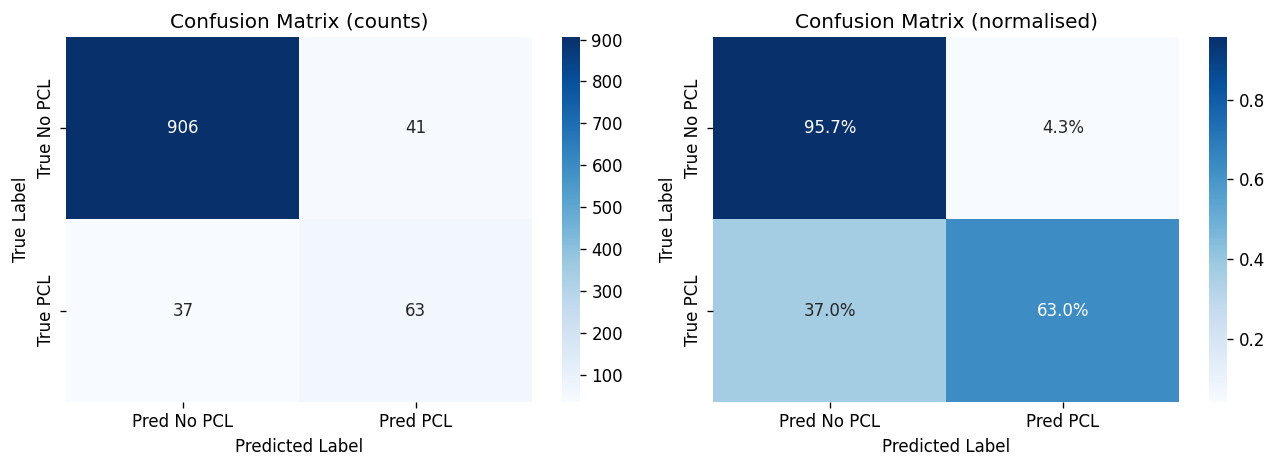

Saved: confusion_matrix.png


In [ ]:
import seaborn as sns

cm = confusion_matrix(y_test, test_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, data, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ["d", ".1%"],
    ["Confusion Matrix (counts)", "Confusion Matrix (normalised)"]
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues", ax=ax,
                xticklabels=["Pred No PCL", "Pred PCL"],
                yticklabels=["True No PCL", "True PCL"])
    ax.set_title(title, fontsize=12)
    ax.set_ylabel("True Label")
    ax.set_xlabel("Predicted Label")

plt.tight_layout()
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()
print("Saved: confusion_matrix.png")


## Precision-Recall Curve

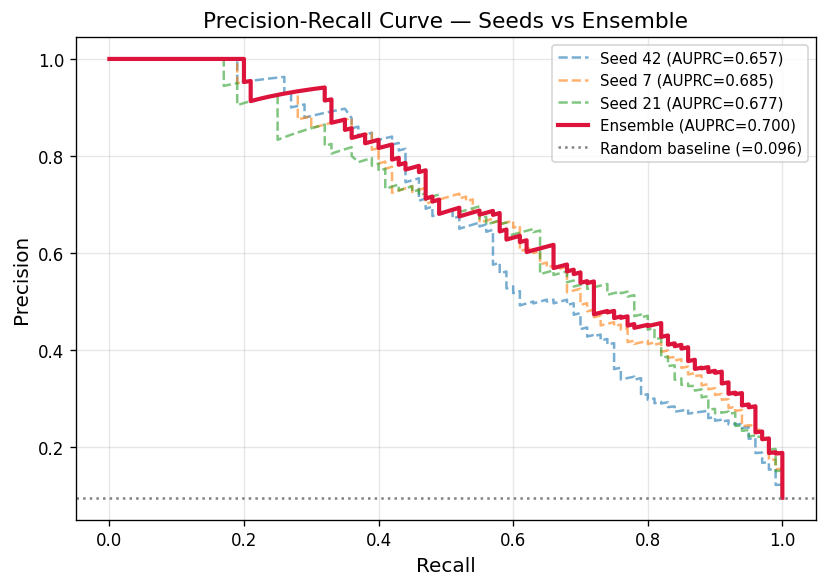

Saved: pr_curve.png


In [ ]:
# Compare each individual seed model vs the ensemble

fig, ax = plt.subplots(figsize=(7, 5))

# Individual seeds
for i, (seed, probs) in enumerate(zip(CFG["seeds"], all_test_probs)):
    prec_s, rec_s, _ = precision_recall_curve(y_test, probs)
    auprc_s = average_precision_score(y_test, probs)
    ax.plot(rec_s, prec_s, linestyle="--", alpha=0.6,
            label=f"Seed {seed} (AUPRC={auprc_s:.3f})")

# Ensemble
prec_e, rec_e, _ = precision_recall_curve(y_test, ensemble_test_probs)
ax.plot(rec_e, prec_e, color="crimson", linewidth=2.5,
        label=f"Ensemble (AUPRC={test_auprc:.3f})")

# Baseline (random classifier at PCL prior)
pcl_prior = y_test.mean()
ax.axhline(pcl_prior, color="grey", linestyle=":", label=f"Random baseline (={pcl_prior:.3f})")

ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curve — Seeds vs Ensemble", fontsize=13)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("pr_curve.png", bbox_inches="tight")
plt.show()
print("Saved: pr_curve.png")


## Error Analysis

In [ ]:
df_test_copy = df_test.copy().reset_index(drop=True)
df_test_copy["ensemble_prob"] = ensemble_test_probs
df_test_copy["pred"]          = test_preds
df_test_copy["gold"]          = y_test

false_negatives = df_test_copy[(df_test_copy["gold"] == 1) & (df_test_copy["pred"] == 0)]
false_positives = df_test_copy[(df_test_copy["gold"] == 0) & (df_test_copy["pred"] == 1)]
true_positives  = df_test_copy[(df_test_copy["gold"] == 1) & (df_test_copy["pred"] == 1)]

print(f"False Negatives (PCL missed): {len(false_negatives)}")
print(f"False Positives (wrongly flagged): {len(false_positives)}")
print(f"True Positives  (correctly caught): {len(true_positives)}")

print("--- 3 Hardest False Negatives (highest prob but still missed) ---")
fn_sorted = false_negatives.sort_values("ensemble_prob", ascending=False).head(3)
for _, row in fn_sorted.iterrows():
    print(f"  prob={row['ensemble_prob']:.3f} | keyword={row['keyword']} | {row['text'][:120]}")
    print()

print("--- 3 Most Confident False Positives ---")
fp_sorted = false_positives.sort_values("ensemble_prob", ascending=False).head(3)
for _, row in fp_sorted.iterrows():
    print(f"  prob={row['ensemble_prob']:.3f} | keyword={row['keyword']} | {row['text'][:120]}")
    print()

false_negatives.to_csv("false_negatives.csv", index=False)
false_positives.to_csv("false_positives.csv", index=False)
print("Saved: false_negatives.csv, false_positives.csv")


False Negatives (PCL missed): 37
False Positives (wrongly flagged): 41
True Positives  (correctly caught): 63
--- 3 Hardest False Negatives (highest prob but still missed) ---
  prob=0.326 | keyword=women | """ Jesus is the Master Feminist because he championed the cause of women , "" she said ."

  prob=0.322 | keyword=poor-families | 10:41am - Parents of children who died must get compensation , free medicine must be provided to poor families across UP

  prob=0.301 | keyword=poor-families | However , this success story is not uncommon . It often happens that people from poor families have more perseverance to

--- 3 Most Confident False Positives ---
  prob=0.960 | keyword=vulnerable | In another development , Eiremiokhae was also bestowed with a Humanitarian Award by the Trinity International University

  prob=0.959 | keyword=refugee | In Nyarugusu , Tanzania 's last major refugee camp , the government and United Nations are trying to end a rootless life

  prob=0.933 | keyword=ho